# Versuch 1: Kalibrierung und Einsatz eines Infrarot-Entfernungsmessers

**Versuchsdatum:** 19.10.2026  
**Teilnehmende:** Artemii Fokin, Rostyslav Yefremov  
**Messprotokoll:** Protokoll_70-10.xlsx

## Ermittlung der Kennlinie des Abstandssensors


#### Daten einlesen und Auswerten

Die ersten 1000 Werte werden übersprungen, danach werden Mittelwert und Standardabweichung berechnet.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
MESSUNGEN = Path("Messungen")

In [3]:
def auswertung(dateiname):
    def komma_zu_punkt(x):
        return float(x.replace(",", "."))

    daten = np.genfromtxt(
        dateiname,
        delimiter=";",
        skip_header=3,
        converters={
            0: komma_zu_punkt,
            1: komma_zu_punkt
        }
    )

    spannung = daten[1000:, 1]

    mittelwert = np.mean(spannung)
    standardabweichung = np.std(spannung, ddof=1)

    return mittelwert, standardabweichung, len(spannung)

In [4]:
mittelwert, std, n = auswertung(MESSUNGEN / "1-10.csv")

print("Mittelwert:", mittelwert, "V")
print("Standardabweichung:", std, "V")

Mittelwert: 1.3535601000565378 V
Standardabweichung: 0.017188014404374594 V


In [5]:
abstaende = []
mittelwerte = []
standardabweichungen = []

for abstand in range(10, 71, 3):
    dateiname = MESSUNGEN / f"1-{abstand}.csv"

    mittelwert, std, n = auswertung(dateiname)

    abstaende.append(abstand)
    mittelwerte.append(mittelwert)
    standardabweichungen.append(std)


In [6]:

print("Abstand (cm) Mittelwert (V) Standardabweichung (V)")

for i in range(len(abstaende)):
    print(f"{abstaende[i]:5d} {mittelwerte[i]:16.6f} {standardabweichungen[i]:18.6f}")


Abstand (cm) Mittelwert (V) Standardabweichung (V)
   10         1.353560           0.017188
   13         1.163616           0.016326
   16         1.025521           0.016028
   19         0.934397           0.017459
   22         0.848925           0.021464
   25         0.777280           0.023362
   28         0.710341           0.022057
   31         0.669110           0.023604
   34         0.652602           0.016609
   37         0.654109           0.017218
   40         0.653228           0.017285
   43         0.651962           0.017351
   46         0.636546           0.023753
   49         0.609408           0.017450
   52         0.600158           0.018687
   55         0.575099           0.023800
   58         0.574083           0.023076
   61         0.558065           0.017104
   64         0.538548           0.024646
   67         0.537162           0.024637
   70         0.516990           0.018341



**Vergleich mit dem Messprotokoll**

Im Messprotokoll sind die Spannungen in mV angegeben. Deshalb werden die berechneten Mittelwerte für den Vergleich von V in mV umgerechnet. Die Differenz ist der berechnete Wert minus dem Wert aus dem Messprotokoll.


In [7]:
from openpyxl import load_workbook

# Die Werte aus dem Excel-Messprotokoll einlesen.
arbeitsmappe = load_workbook("Protokoll_70-10.xlsx", data_only=True)
blatt = arbeitsmappe["Tabelle1"]
protokoll = {}

for zeile in range(2, 23):
    abstand = blatt.cell(zeile, 1).value
    spannung_mV = blatt.cell(zeile, 2).value
    protokoll[abstand] = spannung_mV

arbeitsmappe.close()

print("Abstand (cm) | Protokoll (mV) | Berechnet (mV) | Differenz (mV)")
differenzen = []

for abstand, mittelwert in zip(abstaende, mittelwerte):
    berechnet_mV = mittelwert * 1000
    protokoll_mV = protokoll[abstand]
    differenz = berechnet_mV - protokoll_mV
    differenzen.append(differenz)
    print(f"{abstand:12d} | {protokoll_mV:14.3f} | {berechnet_mV:14.3f} | {differenz:14.3f}")

print(f"\nGrößte absolute Differenz: {max(abs(d) for d in differenzen):.3f} mV")

Abstand (cm) | Protokoll (mV) | Berechnet (mV) | Differenz (mV)
          10 |       1354.000 |       1353.560 |         -0.440
          13 |       1164.000 |       1163.616 |         -0.384
          16 |       1026.000 |       1025.521 |         -0.479
          19 |        934.400 |        934.397 |         -0.003
          22 |        848.900 |        848.925 |          0.025
          25 |        777.300 |        777.280 |         -0.020
          28 |        710.300 |        710.341 |          0.041
          31 |        669.100 |        669.110 |          0.010
          34 |        652.600 |        652.602 |          0.002
          37 |        654.100 |        654.109 |          0.009
          40 |        653.200 |        653.228 |          0.028
          43 |        652.000 |        651.962 |         -0.038
          46 |        636.600 |        636.546 |         -0.054
          49 |        609.400 |        609.408 |          0.008
          52 |        600.200 |        6

#### Darstellung der Kennlinie.

Die berechneten Mittelwerte werden in Abhängigkeit vom Abstand dargestellt.

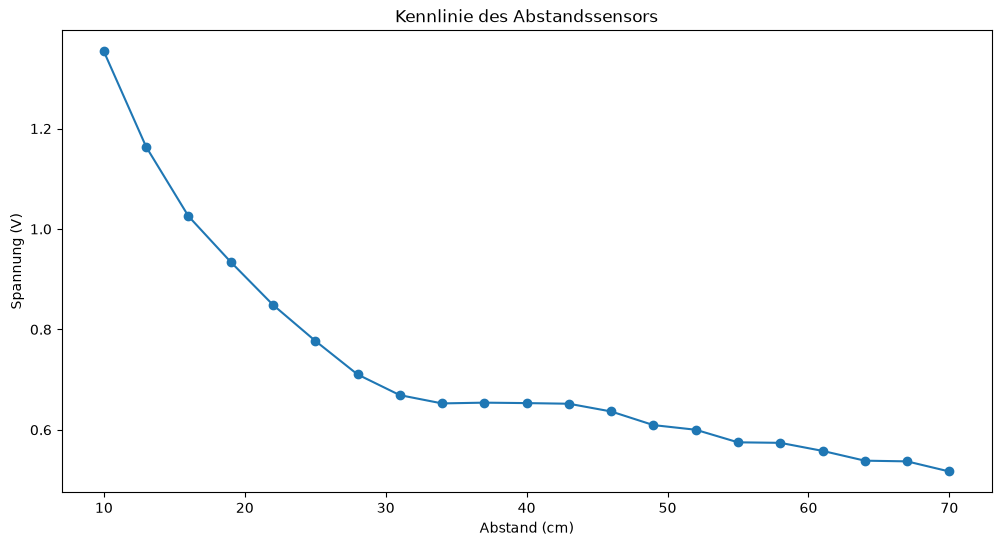

In [8]:
plt.figure(figsize = (12, 6))

plt.plot(abstaende, mittelwerte, "o-")

plt.xlabel("Abstand (cm)")
plt.ylabel("Spannung (V)")
plt.title("Kennlinie des Abstandssensors")

plt.show()

Die Ausgangsspannung nimmt mit zunehmendem Abstand insgesamt ab. Die Kennlinie ist nichtlinear. Zwischen 34 cm und 43 cm bleibt die Spannung nahezu konstant.


## Modellierung der Kennlinie durch lineare Regression

#### Logarithmierung der Messwerte

In [9]:
lg_spannung = np.log(mittelwerte)
lg_abstand = np.log(abstaende)

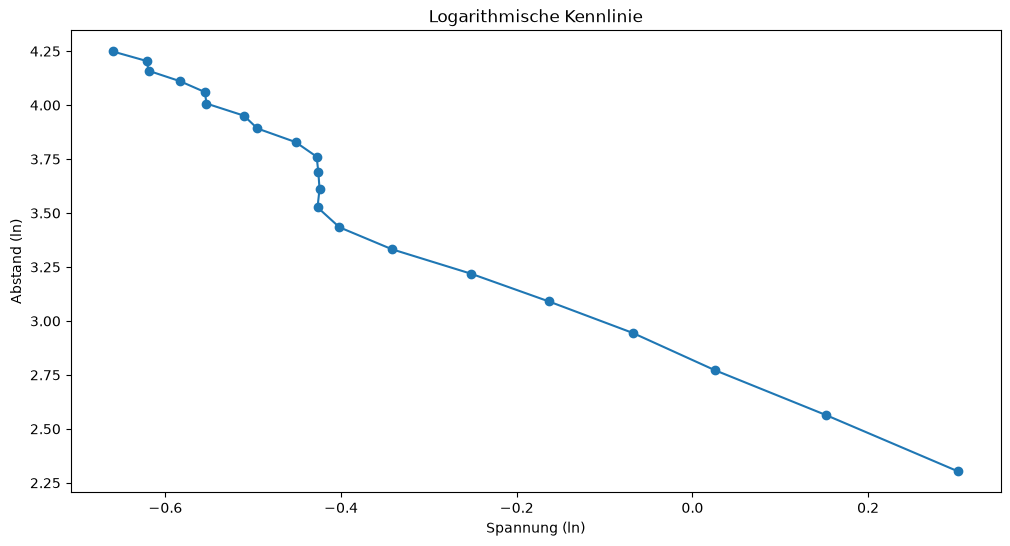

In [10]:
plt.figure(figsize = (12,6))

plt.plot(lg_spannung, lg_abstand, "o-")

plt.xlabel("Spannung (ln)")
plt.ylabel("Abstand (ln)")
plt.title("Logarithmische Kennlinie")

plt.show()

#### Lineare Regression

Wird mit np.polyfit() bestimmt

In [11]:
a, b = np.polyfit(lg_spannung, lg_abstand, 1)
print(a)
print(b)

-2.0950950266132526
2.809205365739977


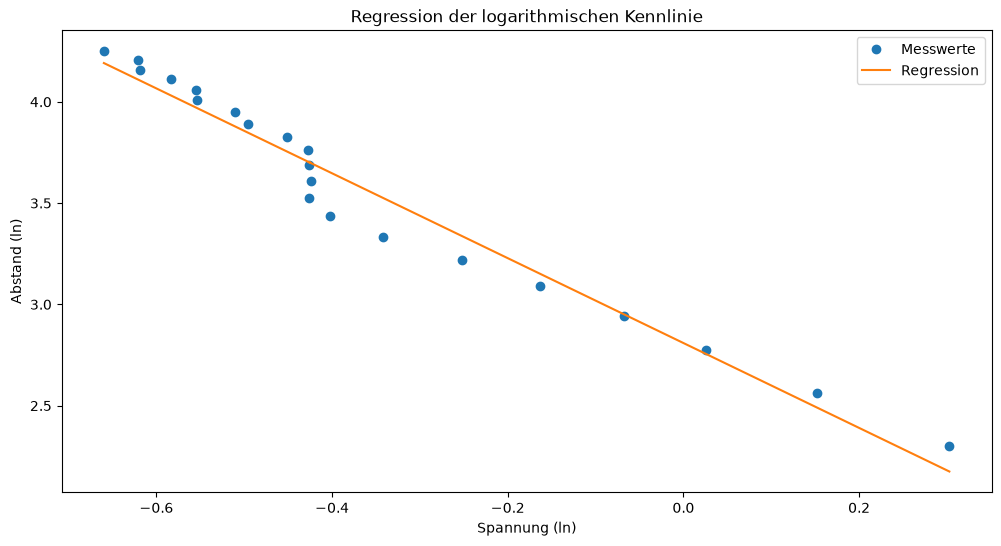

In [12]:
plt.figure(figsize = (12,6))

plt.plot(lg_spannung, lg_abstand, "o", label = "Messwerte")
plt.plot(lg_spannung, a*lg_spannung + b, "-", label = "Regression")

plt.xlabel("Spannung (ln)")
plt.ylabel("Abstand (ln)")
plt.title("Regression der logarithmischen Kennlinie")

plt.legend()
plt.show()


### Regression im Bereich von 10 bis 31 cm

Ab etwa 34 cm bleibt die Spannung nahezu konstant.
Deshalb wird zusätzlich eine Regression für den Bereich von 10 bis 31 cm berechnet.


In [13]:

abstaende_kurz = abstaende[:8]
mittelwerte_kurz = mittelwerte[:8]

a_kurz, b_kurz = np.polyfit(np.log(mittelwerte_kurz), np.log(abstaende_kurz), 1)

print(f"a = {a_kurz:.4f}")
print(f"b = {b_kurz:.4f}")


a = -1.5975
b = 2.8082


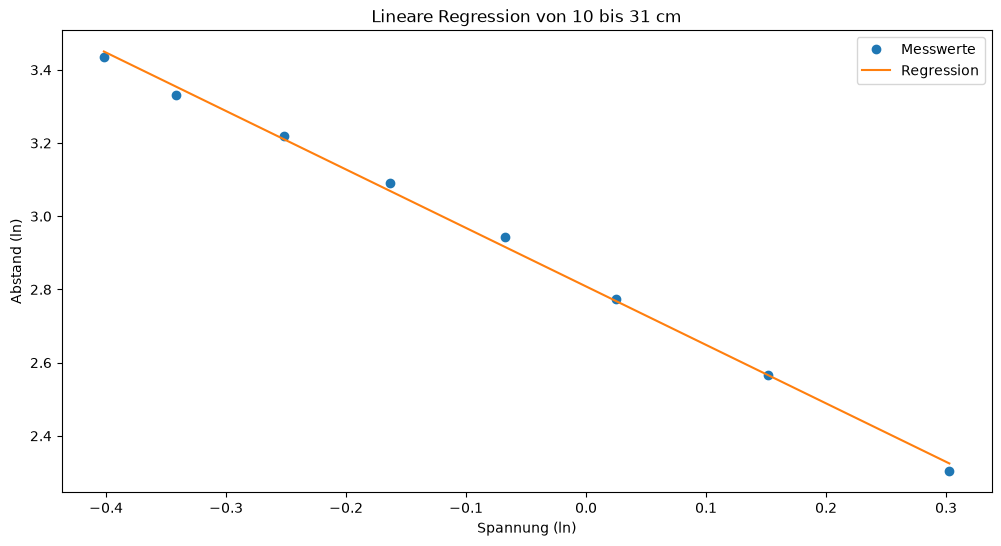

In [14]:
plt.figure(figsize=(12, 6))

plt.plot(np.log(mittelwerte_kurz), np.log(abstaende_kurz), "o", label="Messwerte")

plt.plot(np.log(mittelwerte_kurz), a_kurz * np.log(mittelwerte_kurz) + b_kurz, "-", label="Regression")

plt.xlabel("Spannung (ln)")
plt.ylabel("Abstand (ln)")
plt.title("Lineare Regression von 10 bis 31 cm")

plt.legend()
plt.show()


Die Messwerte zwischen 10 und 31 cm lassen sich durch eine Gerade besser annähern.


#### Kalibrierfunktion

Die Kalibrierfunktion:
$$
d=e^b\cdot U^a
$$
Mit den berechneten Parametern:
$$
d=e^{2{,}8092}\cdot U^{-2{,}0951}
$$

In [15]:
def abstand_berechnen(spannung):
    return np.exp(b) * spannung**a

print("a =", a)
print("b =", b)

print(f"Abstand bei 1V: {abstand_berechnen(1):.2f} cm")

a = -2.0950950266132526
b = 2.809205365739977
Abstand bei 1V: 16.60 cm


#### Überprüfung der Kalibrierfunktion

Die berechneten Abstände werden mit tatsächlichen Messabständen verglichen.

In [16]:
print("Abstand (cm) | Berechnet mit der Formel (cm) | Abweichung(cm)")
for i in range(len(abstaende)):
    berechnet = abstand_berechnen(mittelwerte[i])
    fehler = berechnet - abstaende[i]

    
    print(f"{abstaende[i]:7d} {berechnet:25.2f} {fehler:24.2f}")

Abstand (cm) | Berechnet mit der Formel (cm) | Abweichung(cm)
     10                      8.80                    -1.20
     13                     12.08                    -0.92
     16                     15.74                    -0.26
     19                     19.13                     0.13
     22                     23.39                     1.39
     25                     28.14                     3.14
     28                     33.98                     5.98
     31                     38.51                     7.51
     34                     40.58                     6.58
     37                     40.39                     3.39
     40                     40.50                     0.50
     43                     40.67                    -2.33
     46                     42.76                    -3.24
     49                     46.84                    -2.16
     52                     48.37                    -3.63
     55                     52.89                    

Besonders im Bereich von 30 bis 40 cm treten größere Abweichungen auf, da sich die Spannung dort kaum verändert. 

## Flächenmessung mit Fehlerrechnung

#### Spannungsmessung und Messfehler

In [17]:
mittelwert_L, std_L, n_L = auswertung(MESSUNGEN / "1-A4-L.csv")
mittelwert_B, std_B, n_B = auswertung(MESSUNGEN / "1-A4-B.csv")

print(f"Länge: Mittelwert = {mittelwert_L:.6f} V, Standardabweichung = {std_L:.6f} V, n = {n_L}")
print(f"Breite: Mittelwert = {mittelwert_B:.6f} V, Standardabweichung = {std_B:.6f} V, n = {n_B}")

Länge: Mittelwert = 0.650089 V, Standardabweichung = 0.017568 V, n = 95158
Breite: Mittelwert = 0.870902 V, Standardabweichung = 0.023381 V, n = 95158



Die Unsicherheit des Mittelwerts wird berechnet mit:

$$
s_{\bar U} = \frac{s_U}{\sqrt{n}}
$$

Dabei ist n die Anzahl der verwendeten Messwerte.

Die folgenden Unsicherheiten berücksichtigen nur die statistischen Schwankungen der Spannung. Fehler beim Einstellen des Abstands und Abweichungen der Kalibrierfunktion sind nicht enthalten.


In [18]:
fehler_U_L = std_L / np.sqrt(n_L)
print(f"Spannung der langen Seite: ({mittelwert_L:.6f} ± {fehler_U_L:.6f}) V")

Spannung der langen Seite: (0.650089 ± 0.000057) V


#### Vertrauensbereiche

Die Vertrauensbereiche für 68 % und 95 %:

$$
\quad \bar U \pm s_{\bar U}
$$

$$
\quad \bar U \pm 1{,}96 \cdot s_{\bar U}
$$


In [19]:
fehler_68 = fehler_U_L
fehler_95 = 1.96 * fehler_U_L

print(f"68 %: ({mittelwert_L:.6f} ± {fehler_68:.6f}) V")
print(f"95 %: ({mittelwert_L:.5f} ± {fehler_95:.5f}) V")

68 %: (0.650089 ± 0.000057) V
95 %: (0.65009 ± 0.00011) V


#### Abstandsmessung mit Fehlerfortpflanzung


Die Unsicherheit der Spannung wird auf den Abstand übertragen:

$$
d = e^b \cdot U^a
$$

$$
\Delta d = \left|e^b \cdot a \cdot U^{a-1}\right| \cdot \Delta U
$$


In [20]:
abstand_L = abstand_berechnen(mittelwert_L)

fehler_L = abs(np.exp(b) * a * mittelwert_L ** (a-1)) * fehler_U_L

print(f"Länge: ({abstand_L:.4f} ± {fehler_L:.4f}) cm (nur statistische Unsicherheit)")

Länge: (40.9131 ± 0.0075) cm (nur statistische Unsicherheit)


#### Messung der Breite

In [21]:
fehler_U_B = std_B / np.sqrt(n_B)

abstand_B = abstand_berechnen(mittelwert_B)

fehler_B = abs(np.exp(b) * a * mittelwert_B**(a-1)) * fehler_U_B

print(f"Spannung der kurzen Seite: ({mittelwert_B:.6f} ± {fehler_U_B:.6f}) V")
print(f"Breite: ({abstand_B:.4f} ± {fehler_B:.4f}) cm (nur statistische Unsicherheit)")

Spannung der kurzen Seite: (0.870902 ± 0.000076) V
Breite: (22.1714 ± 0.0040) cm (nur statistische Unsicherheit)


#### Flächenberechnung und Ausgabe

In [22]:
flaeche = abstand_L * abstand_B
print(f"Fläche: {flaeche:.2f} cm²")

Fläche: 907.10 cm²


Die Messunsicherheit nach dem Gaußschen Fehlerfortpflanzungsgesetz:

$$
\Delta A = \sqrt{(B \cdot \Delta L)^2 + (L \cdot \Delta B)^2}
$$


In [23]:
fehler_A = np.sqrt((abstand_B * fehler_L) ** 2 + (abstand_L * fehler_B) ** 2)
print(f"Fläche: ({flaeche:.2f} ± {fehler_A:.2f}) cm² (nur statistische Unsicherheit)")

Fläche: (907.10 ± 0.23) cm² (nur statistische Unsicherheit)



### Flächenberechnung mit der neuen Regression

Die Länge und Breite werden zusätzlich mit der
Kalibrierfunktion für den Bereich von 10 bis 31 cm berechnet.


In [24]:
laenge_neu = np.exp(b_kurz) * mittelwert_L**a_kurz
breite_neu = np.exp(b_kurz) * mittelwert_B**a_kurz

flaeche_neu = laenge_neu * breite_neu

print(f"Länge: {laenge_neu:.2f} cm")
print(f"Breite: {breite_neu:.2f} cm")
print(f"Fläche: {flaeche_neu:.2f} cm²")


Länge: 32.99 cm
Breite: 20.68 cm
Fläche: 682.14 cm²


In [25]:
fehler_L_neu = abs(np.exp(b_kurz) * a_kurz * mittelwert_L**(a_kurz-1)) * fehler_U_L
fehler_B_neu = abs(np.exp(b_kurz) * a_kurz * mittelwert_B**(a_kurz-1)) * fehler_U_B

fehler_A_neu = np.sqrt((breite_neu * fehler_L_neu)**2 + (laenge_neu * fehler_B_neu)**2)

print(f"Fläche: ({flaeche_neu:.2f} ± {fehler_A_neu:.4f}) cm² (nur statistische Unsicherheit)")


Fläche: (682.14 ± 0.1346) cm² (nur statistische Unsicherheit)


## Fazit

Mit der Kalibrierung über den gesamten Messbereich von 10 bis 70 cm ergab sich für das DIN-A4-Blatt eine Fläche von 907,10 cm². Dies entspricht einer Abweichung von 45,4 % gegenüber dem tatsächlichen Wert von 623,70 cm².

Da die Kennlinie im Bereich von etwa 34 bis 43 cm nahezu konstant verläuft, wurde zusätzlich eine Kalibrierung im Bereich von 10 bis 31 cm durchgeführt. Damit ergab sich eine Fläche von 682,14 cm² mit einer Abweichung von 9,4 %.

Allerdings liegt die Längenmessung knapp außerhalb des neuen Kalibrierbereichs. Die berechneten Messunsicherheiten berücksichtigen nur die statistischen Schwankungen der Spannung.